### __Anna Kaczyńska, Kamila Mosińska__
## PROJECT 3: STIRRED (NOT SHAKEN)
-----

### ABSTRACT

This assignment focused on implementing a general ODE solver, using the forward Euler method and Runge-Kutta algorithms (second order and fourth order). We implemented a mixing tanks model, to model the spread of a tracer solution traveling through an aortic arch. We compared our ODE model to the CFD flow simulations. Additionally, we conducted brief analysis of the model on known aneurysm simulations.

### INTRODUCTION


The problems to be investigated in this project concern obtaining the general solutions to ODE systems through the use of Euler and Runge-Kutta methods and comparing their results to those of CFD, assessing their accuracy.


-----

## EXERCISE 1:
### ODE SOLVER
### PART 1

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [ ]:
class ode_solver:

    def __init__(self, func, params, h, y0, t0, tf, method='euler'):
        self.f = func
        self.params = params
        self.h = h
        self.y0 = y0
        self.t0 = t0
        self.tf = tf
        self.method = method
        self.Y = []
        self.T = []

    def euler(self, t, y, h):
        return h * self.f(t, y, self.params)

    def rk2(self, t, y, h):
        k1 = h * self.f(t, y, self.params)
        k2 = h * self.f(t + h/2, y + 1/2*k1, self.params)
        return k2

    def rk4(self, t, y, h):
        k1 = h * self.f(t, y, self.params)
        k2 = h * self.f(t + h/2, y + 1/2*k1, self.params)
        k3 = h * self.f(t + h/2, y + 1/2*k2, self.params)
        k4 =h * self.f(t + h, y + k3, self.params)
        return 1/6 * (k1 + 2*k2 + 2*k3 + k4)
    
    def solver(self):
        self.Y = []
        self.T = []
        self.Y.append(self.y0.copy())
        self.T.append(self.t0)
        h = self.h
        t0 = self.t0
        tf = self.tf
        method = self.method
        y_old = self.y0

        for t in np.arange(t0, tf, h):
            h = min(self.h, self.tf - t)
            
            if method == 'euler':
                y_new = y_old + self.euler(t,y_old,h)
            elif method == 'rk2':
                y_new = y_old + self.rk2(t,y_old,h)
            elif method == 'rk4':
                y_new = y_old + self.rk4(t,y_old,h)

            y_old = y_new
            self.Y.append(y_old)
            self.T.append(t + h)

        Y = np.array(self.Y)
        T = np.array(self.T)

        return Y, T

### PART 2

In [58]:
def C_concentration(t, C, params):

    n, tau, C_in = params

    dCdt = np.zeros(n)
    dCdt[0] = (n/tau) * (C_in - C[0])

    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    return dCdt

results = {}
for n in [1, 2, 3]:
    params = (n, 2, 0)

    C0 = np.zeros(n)
    C0[0] = 1
    y0 = C0

    solve = ode_solver(C_concentration, params, 0.1, C0, 0, 10, method = 'rk4')
    Y, T = solve.solver()

    results[n] = (Y,T)


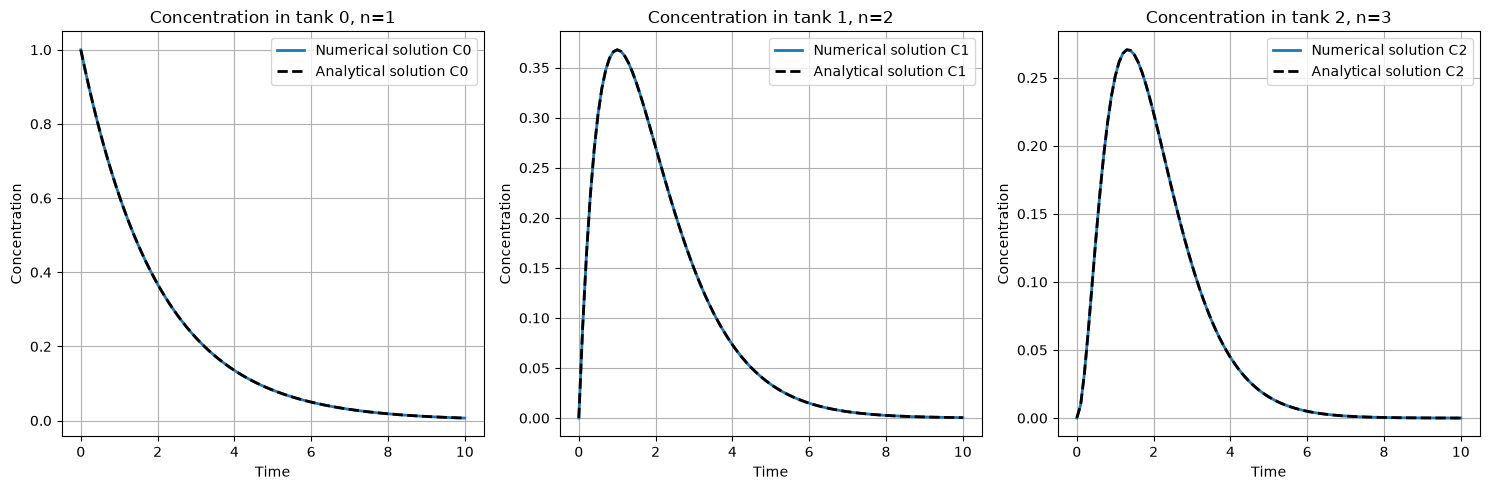

In [59]:
tau = 2

Y_values = [results[n][0] for n in [1, 2, 3]]
T_values = [results[n][1] for n in [1, 2, 3]]

C_exact = [
    np.exp(-T_values[0]/tau),
    (2*T_values[1]/tau) * np.exp(-2*T_values[1]/tau),
    (9*T_values[2]**2/(2*tau**2)) * np.exp(-3*T_values[2]/tau)
]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax[i].plot(T_values[i], Y_values[i][:,i], # change Y_values[i][:,i] to Y_values[i] if you want to display all the solutions
               label=f'Numerical solution C{i}', linewidth=2)

    ax[i].plot(T_values[i], C_exact[i], '--',
               label=f'Analytical solution C{i}',
               color='black', linewidth=2)

    ax[i].set_xlabel("Time")
    ax[i].set_ylabel("Concentration")
    ax[i].set_title(f"Concentration in tank {i}, n={i+1}")
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

### PART 3

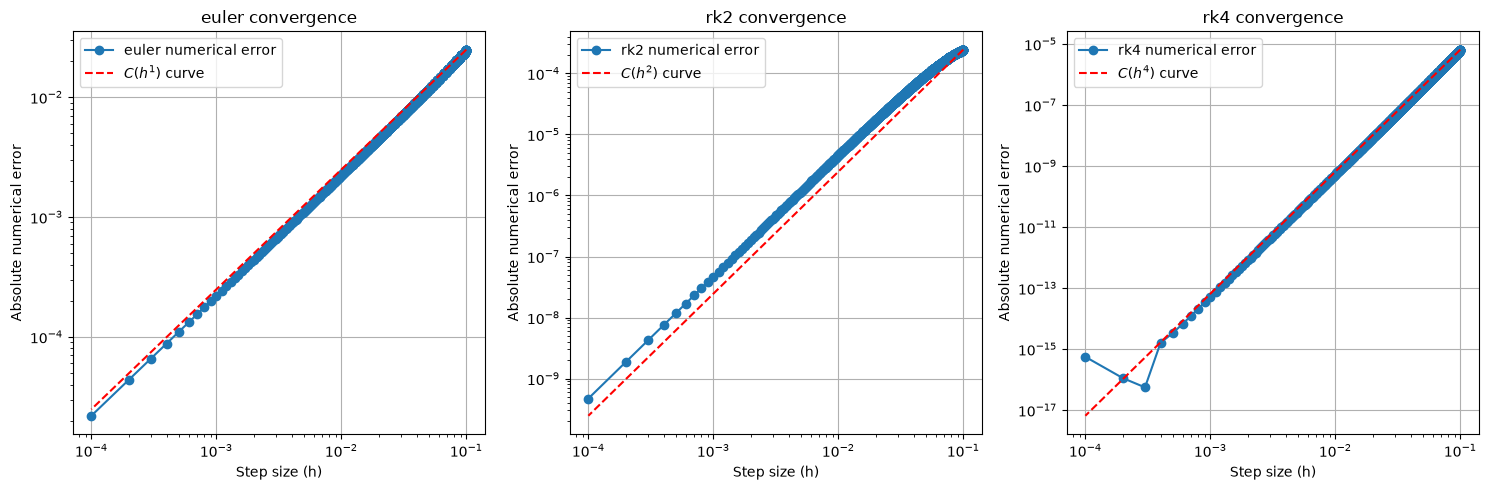

In [60]:
# for n = 3
n = 3
h = np.linspace(0.1, 0.0001, 1000)
t_exact = 1

C_exact_3 = (9*t_exact**2/(2*tau**2)) * np.exp(-3*t_exact/tau)

methods = ['euler', 'rk2', 'rk4']
orders = {'euler': 1, 'rk2': 2, 'rk4': 4}
errors = {}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, method in enumerate(methods):

    errors[method] = []
    
    for step in h:
        solve = ode_solver(C_concentration, (n, tau, 0),step, C0, 0, t_exact, method=method)
        Y, T = solve.solver()

        error = abs(C_exact_3 - Y[-1, 2])
        errors[method].append(error)

    order = orders[method]

    # scaling constant based on the first error
    C = errors[method][0] / h[0]**order
    
    # theoretical convergence curve
    theoretical_error = C * h**order

    ax[i].loglog(h, errors[method], 'o-', label=f'{method} numerical error')
    ax[i].loglog(h, theoretical_error, '--r', label=f'$C(h^{order})$ curve')

    ax[i].set_xlabel('Step size (h)')
    ax[i].set_ylabel('Absolute numerical error')
    ax[i].set_title(f'{method} convergence')
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

As seen on the plots above, each of the methods seems to follow the theoretical curves of the same order. The Euler's method is least accurate, followed by rk2, with rk4 having the lowest errors - hence in the calculations below our chosen method of solving ODE's here will be the fourth order Runge-Kutta method.

-----
## EXERCISE 2:
### FITTING CSTR MODEL TO CFD MODEL
### PART 1

In [61]:
healthy_rect_1s = pd.read_csv('data/Healthy_rect_1s.csv')
healthy_rect_1s

,Time,Concentration
0,0.00,0.000000e+00
1,0.02,0.000000e+00
2,0.04,0.000000e+00
3,0.06,0.000000e+00
4,0.08,0.000000e+00
...,...,...
246,4.92,8.620000e-06
247,4.94,4.980000e-06
248,4.96,2.020000e-06
249,4.98,2.510000e-08


In [62]:
M_inj = 83.333

time = healthy_rect_1s['Time'].to_numpy()
C_out = healthy_rect_1s['Concentration'].to_numpy()

integral = np.trapezoid(C_out,time)
q = (60/1000)* (M_inj / integral)
print(q)

5.005983664163233


### PART 2

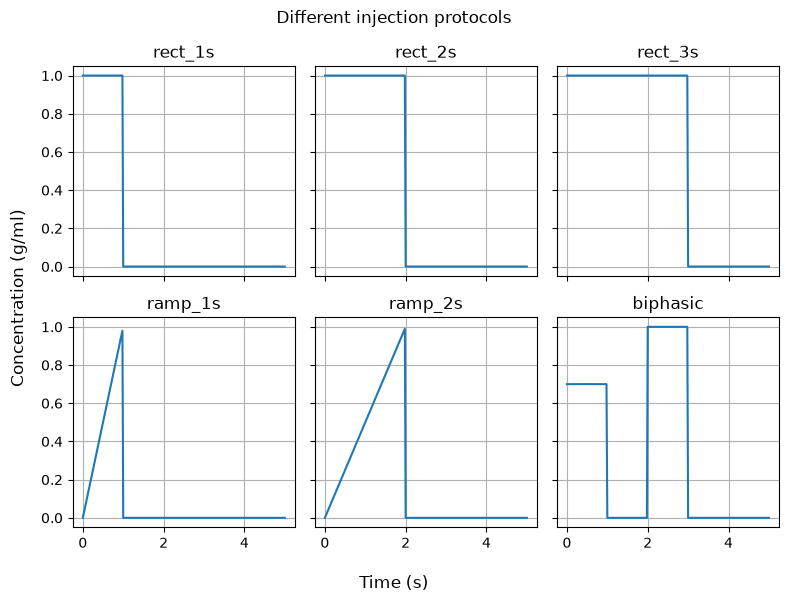

In [63]:
def c_inj(t,ti=np.array([0,1.,1.,2.,2.,3.,3.]),qi=np.array([0,0,0,0,0,0,0]),ci=np.array([1,1,0,0,0,0,0])):
    return np.interp(t,ti,ci),np.interp(t,ti,qi)

rect_1s = c_inj(time)[0]
rect_2s = c_inj(time, ci=np.array([1,1,1,1,0,0,0]))[0]
rect_3s = c_inj(time, ci=np.array([1,1,1,1,1,1,0]))[0]
ramp_1s = c_inj(time, ci=np.array([0,1,0,0,0,0,0]))[0]
ramp_2s = c_inj(time, ci=np.array([0,0.5,0.5,1,0,0,0]))[0]
biphasic = c_inj(time, ci=np.array([0.7,0.7,0,0,1,1,0]))[0]

protocols = [rect_1s, rect_2s, rect_3s, ramp_1s, ramp_2s, biphasic]
names = ['rect_1s', 'rect_2s', 'rect_3s','ramp_1s', 'ramp_2s', 'biphasic']

fig, ax = plt.subplots(2, 3, figsize=(8,6), sharex=True, sharey = True)

for a, protocol, name in zip(ax.flat, protocols, names):
    a.plot(time, protocol)
    a.set_title(name)
    a.grid()

fig.supxlabel('Time (s)')
fig.supylabel('Concentration (g/ml)')
plt.suptitle('Different injection protocols')
plt.tight_layout()
plt.show()

### PART 3

In [64]:
def C_concentration(t, C, params):

    n, tau, C_in = params
    C_in_t = np.interp(t, time, C_in)

    dCdt = np.zeros(n)
    dCdt[0] = (n/tau) * (C_in_t - C[0])

    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    return dCdt

In [65]:
results = []

for n in range(1, 21):

    def simulation(time, tau):

        params = (n, tau, rect_1s)
        C0 = np.zeros(n)

        solve = ode_solver(C_concentration,params,0.01,C0,0,5,method='rk4')
        Y, T = solve.solver()

        return np.interp(time, T, Y[:, -1])

    popt, pcov = curve_fit(
        simulation,
        time,
        C_out,
        p0=[15],
        bounds=([0.001], [1000])
    )

    tau_opt = popt[0]
    
    C_sim = simulation(time, tau_opt)
    SSR = np.sum((C_out - C_sim)**2)

    results.append((n, tau_opt, SSR))

In [66]:
results = np.array(results)

best_idx = np.argmin(results[:, 2])

best_n = int(results[best_idx, 0])
best_tau = results[best_idx, 1]
best_SSR = results[best_idx, 2]

print("Best number of compartments:", best_n)
print("Best tau:", best_tau)
print("Best SSR:", best_SSR)

Best number of compartments: 14
Best tau: 2.3947312745424214
Best SSR: 3.5183041946360114


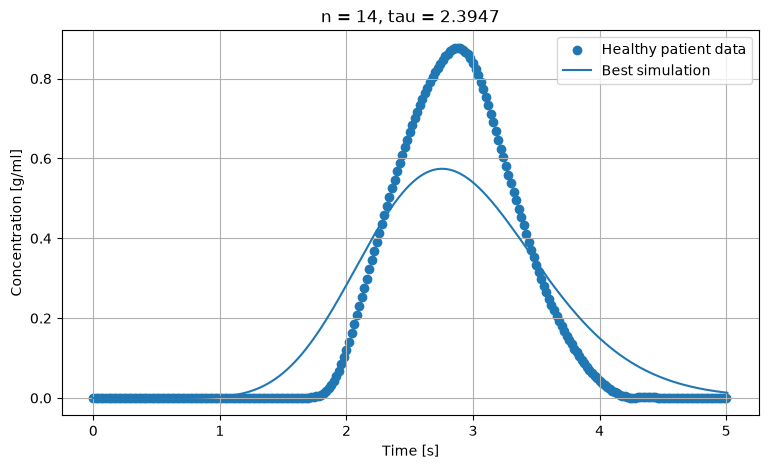

In [67]:
params = (best_n, best_tau, rect_1s)

C0 = np.zeros(best_n)

solve = ode_solver(C_concentration,params,0.01,C0,0,5.01,method='rk4')
Y, T = solve.solver()

plt.figure(figsize=(9, 5))

plt.scatter(time, C_out, label='Healthy patient data')
plt.plot(T, Y[:, -1], label='Best simulation')

plt.xlabel('Time [s]')
plt.ylabel('Concentration [g/ml]')
plt.title(f'n = {best_n}, tau = {best_tau:.4f}')
plt.legend()
plt.grid()
plt.show()

### PART 4

In [68]:
healthy_rect_2s = pd.read_csv('data/Healthy_rect_2s.csv')
healthy_ramp_2s = pd.read_csv('data/Healthy_ramp_2s.csv')
healthy_biphasic = pd.read_csv('data/Healthy_biphasic.csv')

time_rect_2s = healthy_rect_2s['Time'].to_numpy()
C_out_rect_2s = healthy_rect_2s['Concentration'].to_numpy()
time_ramp_2s = healthy_ramp_2s['Time'].to_numpy()
C_out_ramp_2s = healthy_ramp_2s['Concentration'].to_numpy()
time_biphasic = healthy_biphasic['Time'].to_numpy()
C_out_biphasic = healthy_biphasic['Concentration'].to_numpy()

datasets = {
    'rect_2s': (time_rect_2s, C_out_rect_2s, rect_2s),
    'ramp_2s': (time_ramp_2s, C_out_ramp_2s, ramp_2s),
    'biphasic': (time_biphasic, C_out_biphasic, biphasic)
}

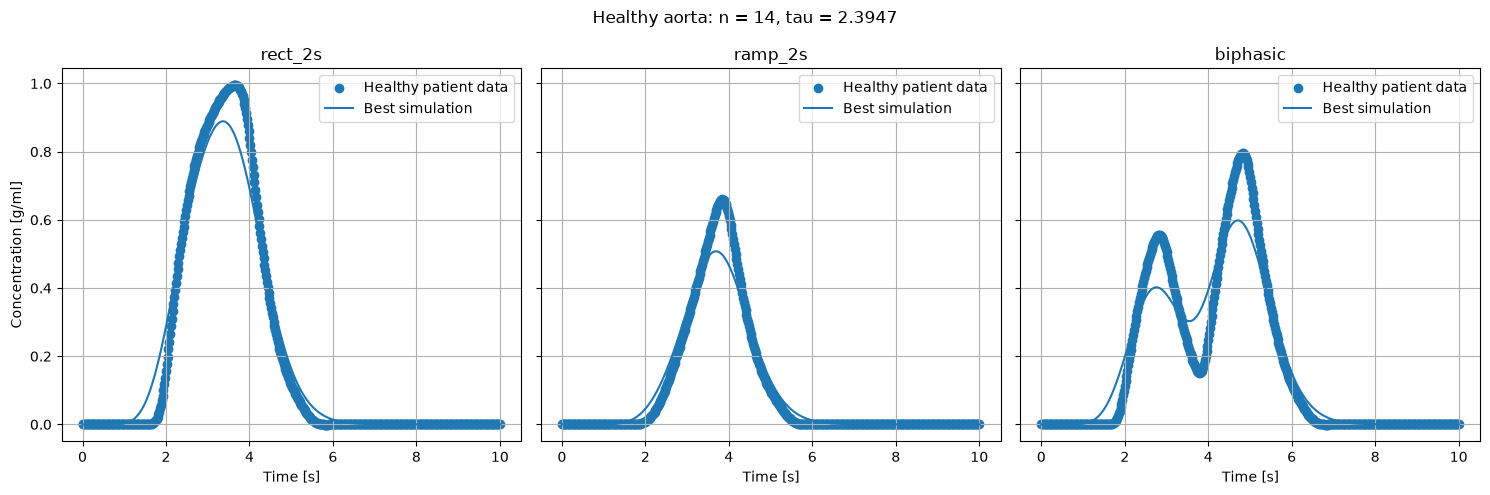

In [69]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for a, (name, (time_data, C_data, protocol)) in zip(ax, datasets.items()):

    params = (best_n, best_tau, protocol)
    C0 = np.zeros(best_n)

    solve = ode_solver(C_concentration,params,0.01,C0,0,10.01,method='rk4')
    Y, T = solve.solver()

    a.scatter(time_data, C_data, label='Healthy patient data')
    a.plot(T, Y[:, -1], label='Best simulation')

    a.set_title(name)
    a.set_xlabel('Time [s]')
    a.grid()
    a.legend()

ax[0].set_ylabel('Concentration [g/ml]')

plt.suptitle(f'Healthy aorta: n = {best_n}, tau = {best_tau:.4f}')
plt.tight_layout()
plt.show()

We decided to model protocols rect_2s, ramp_2s and biphasic. The results we obtained from the model are quite optimistic; the optimal number of compartments for our model is 14, with tau = 2.39 and the sum-of-squared residuals being 3.52. Visually, on rect_1s the results are not that great, but applying the same model to the other 3 protocols yielded better comparisons. The CSTR model seems to be good at reciprocating the distributions of the data; most errors come from over or underestimating the peaks of the distributions themselves.


## EXERCISE 3:
### Aorta with aneurysm
### PART 1

In [70]:
unhealthy_rect_1s = pd.read_csv('data/Aneurysm_rect_1s.csv')
unhealthy_rect_1s

,Time,Concentration
0,0.00,0.000000
1,0.02,0.000000
2,0.04,0.000000
3,0.06,0.000000
4,0.08,0.000000
...,...,...
246,4.92,0.008076
247,4.94,0.008012
248,4.96,0.007968
249,4.98,0.007947


In [71]:
time_rect_1s = unhealthy_rect_1s['Time'].to_numpy()
C_out_rect_1s = unhealthy_rect_1s['Concentration'].to_numpy()

In [72]:
results = []

for n in range(1, 21):

    def simulation(time_rect_1s, tau):

        params = (n, tau, rect_1s)
        C0 = np.zeros(n)

        solve = ode_solver(C_concentration,params,0.01,C0,0,5.01,method='rk4')
        Y, T = solve.solver()

        return np.interp(time_rect_1s, T, Y[:, -1])

    popt, pcov = curve_fit(
        simulation,
        time_rect_1s,
        C_out_rect_1s,
        p0=[15],
        bounds=([0.001], [1000])
    )

    tau_opt = popt[0]
    C_sim = simulation(time_rect_1s, tau_opt)

    SSR = np.sum((C_out_rect_1s - C_sim)**2)

    results.append((n, tau_opt, SSR))

In [73]:
results = np.array(results)

best_idx = np.argmin(results[:, 2])

best_n = int(results[best_idx, 0])
best_tau = results[best_idx, 1]
best_SSR = results[best_idx, 2]

print("Best number of compartments:", best_n)
print("Best tau:", best_tau)
print("Best SSR:", best_SSR)

Best number of compartments: 15
Best tau: 2.4760768948691134
Best SSR: 0.6187097257145054


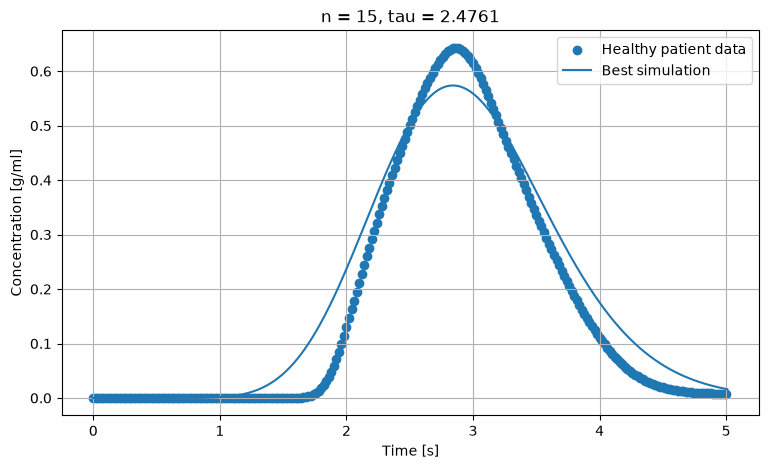

In [74]:
params = (best_n, best_tau, rect_1s)
C0 = np.zeros(best_n)

solve = ode_solver(C_concentration,params,0.01,C0,0,5.01,method='rk4')
Y, T = solve.solver()

plt.figure(figsize=(9, 5))

plt.scatter(time_rect_1s, C_out_rect_1s, label='Healthy patient data')
plt.plot(T, Y[:, -1], label='Best simulation')

plt.xlabel('Time [s]')
plt.ylabel('Concentration [g/ml]')
plt.title(f'n = {best_n}, tau = {best_tau:.4f}')
plt.legend()
plt.grid()
plt.show()

### PART 2

In [75]:
unhealthy_rect_2s = pd.read_csv('data/Aneurysm_rect_2s.csv')
unhealthy_ramp_2s = pd.read_csv('data/Aneurysm_ramp_2s.csv')
unhealthy_biphasic = pd.read_csv('data/Aneurysm_biphasic.csv')

time_rect_2s = unhealthy_rect_2s['Time'].to_numpy()
C_out_rect_2s = unhealthy_rect_2s['Concentration'].to_numpy()
time_ramp_2s = unhealthy_ramp_2s['Time'].to_numpy()
C_out_ramp_2s = unhealthy_ramp_2s['Concentration'].to_numpy()
time_biphasic = unhealthy_biphasic['Time'].to_numpy()
C_out_biphasic = unhealthy_biphasic['Concentration'].to_numpy()

datasets = {
    'rect_2s': (time_rect_2s, C_out_rect_2s, rect_2s),
    'ramp_2s': (time_ramp_2s, C_out_ramp_2s, ramp_2s),
    'biphasic': (time_biphasic, C_out_biphasic, biphasic)
}

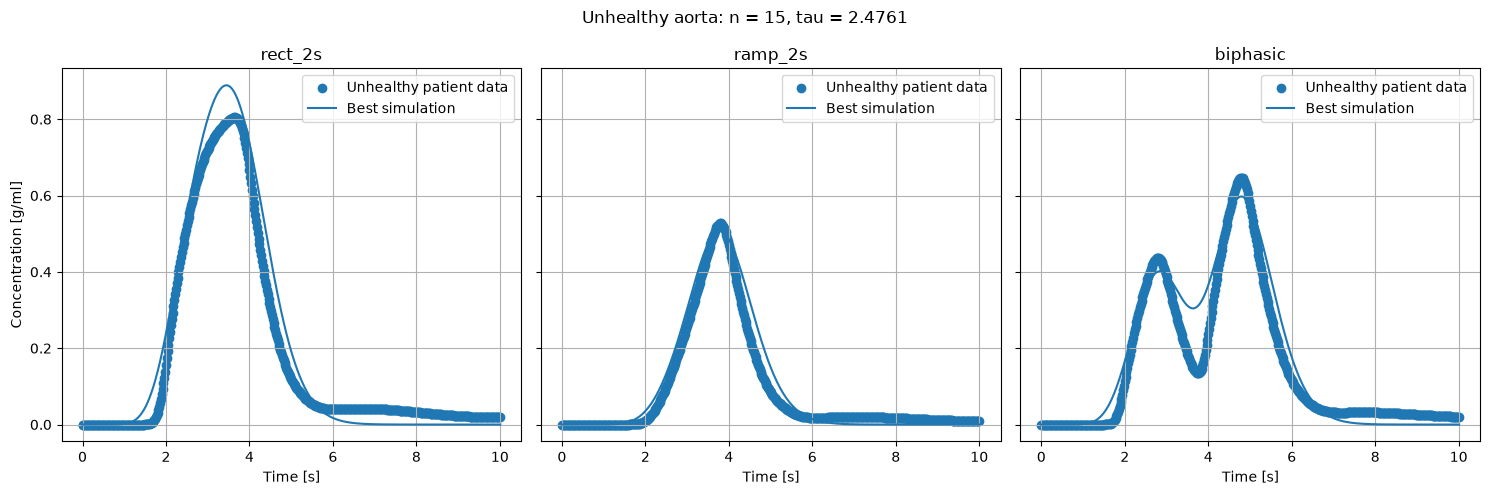

In [76]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for a, (name, (time_data, C_data, protocol)) in zip(ax, datasets.items()):

    params = (best_n, best_tau, protocol)
    C0 = np.zeros(best_n)

    solve = ode_solver(C_concentration,params,0.01,C0,0,10.01,method='rk4')
    Y, T = solve.solver()

    a.scatter(time_data, C_data, label='Unhealthy patient data')
    a.plot(T, Y[:, -1], label='Best simulation')

    a.set_title(name)
    a.set_xlabel('Time [s]')
    a.grid()
    a.legend()

ax[0].set_ylabel('Concentration [g/ml]')

plt.suptitle(f'Unhealthy aorta: n = {best_n}, tau = {best_tau:.4f}')
plt.tight_layout()
plt.show()

### PART 3 & 4

The number of compartments we ended up with is pretty similar. We obtained 14 compartments for the healthy patient data and 15 compartments for the sick patients. We believe the results are similar, due to the nature of the data being similar. We notice that the distributions of the two categories of data are very similar, hence the simulations are also alike. The sick patient data has peaks of noticeably lower-amplitude, which visually fit better to the model we fitted. As well as, the distribution of the sick patients data seems to have a bit of positive kurtosis on the right hand side, which might be caused by the irregular blood-flow due to an aneurysm.

The CSTR model seems to be useful when modeling CFD data. We believe it performed particularly strong across different protocols and it was highly adaptive to changes in the amplitudes and bimodal distributions. It was not overly sensitive to the data, but we attribute it as a strength, because if the model fit every nook and cranny of the data, it would clearly be overfitted and not useful beside this one application.

The limitations of the CSTR model could be it's simplicity. It is a relatively simple to apply model, with not too many variables, but it might suffer in a more rigourous setting, with a higher volume of data and more noise signals in it. The proposed in the next exercise expansion hopefully can help us to fine-tune the solution a bit more, but we recognize that CSTR is a quite generalised approach whose implementation, as it is now, would suffer in a Big Data setting.

## EXERCISE 4:
### Extend model
### PART 1

In [77]:
def C_concentration_aneurysm(t, C, params):
    n, tau, C_in, D, VA = params

    CA = C[-1]
    C_in_t = np.interp(t, time, C_in)

    q = 5/60
    V = q*tau/n
    
    dCdt = np.zeros(n+1)
    dCdt[0] = (n/tau) * (C_in_t - C[0])
    
    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    # Exchange between the selected tank and aneurysm
    dCdt[n-1] -= (D/V) * (C[n-1] - CA)

    # Concentration in the aneurysm
    dCdt[-1] = (D/VA) * (C[n-1] - CA)
    
    return dCdt

In [78]:
results = []

n = best_n
tau = best_tau

def simulation(time_rect_1s, D, VA):

    params = (n, tau, rect_1s, D, VA)
    C0 = np.zeros(n+1)

    solve = ode_solver(C_concentration_aneurysm,params,0.01,C0,0,5.01,method='rk4')
    Y, T = solve.solver()

    return np.interp(time_rect_1s, T, Y[:, -2])


popt, pcov = curve_fit(
    simulation,
    time_rect_1s,
    C_out_rect_1s,
    p0=[10*(5/60), 0.1],
    bounds=([0.001, 0.001], [100*(5/60), 10]),
    maxfev=10000
)

D_opt, VA_opt = popt

C_sim = simulation(time_rect_1s, D_opt, VA_opt)
SSR = np.sum((C_out_rect_1s - C_sim)**2)

print("Optimal D:", D_opt)
print("Optimal VA:", VA_opt)
print("SSR:", SSR)

Optimal D: 0.002949871124377475
Optimal VA: 9.999968369280584
SSR: 0.5956339253582662


In [79]:
best_n_aneurysm = best_n
best_tau_aneurysm = best_tau

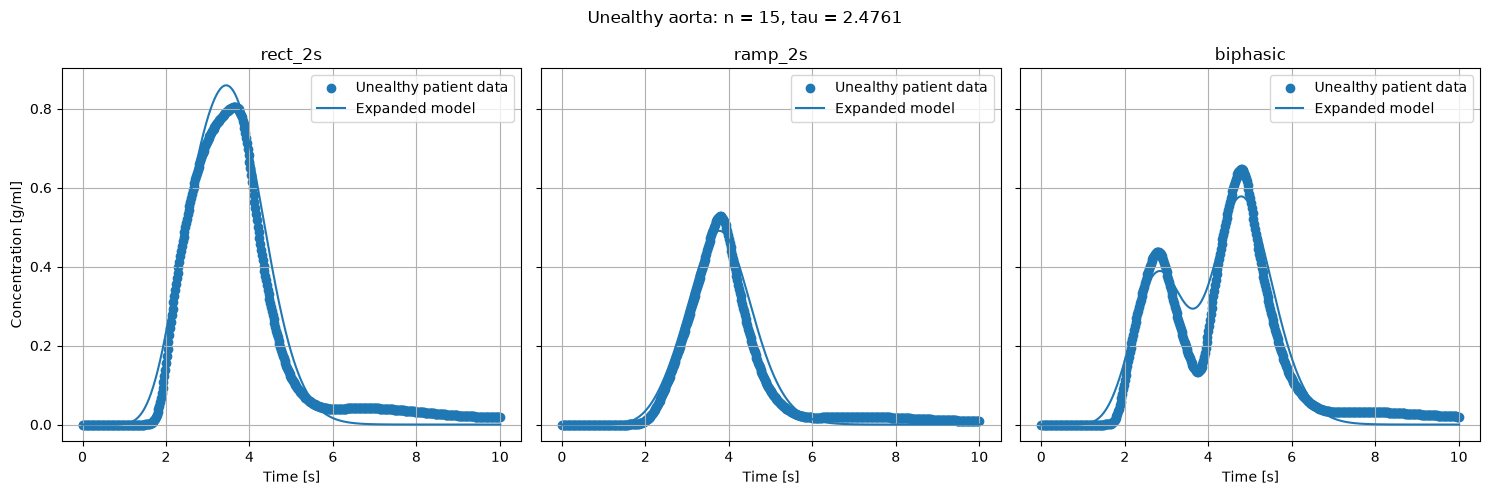

In [80]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for a, (name, (time_data, C_data, protocol)) in zip(ax, datasets.items()):

    params = (best_n, best_tau, protocol, D_opt, VA_opt)
    C0 = np.zeros(best_n + 1)

    solve = ode_solver(C_concentration_aneurysm,params,0.01,C0,0,10.01,method='rk4')
    Y, T = solve.solver()

    a.scatter(time_data, C_data, label='Unealthy patient data')
    a.plot(T, Y[:, -2], label='Expanded model')

    a.set_title(name)
    a.set_xlabel('Time [s]')
    a.grid()
    a.legend()

ax[0].set_ylabel('Concentration [g/ml]')

plt.suptitle(f'Unealthy aorta: n = {best_n}, tau = {best_tau:.4f}')
plt.tight_layout()
plt.show()

After extension of CSTR model, we can match the data slightly better. SSR for extended model is equal to 0.5956, while for the baseline model - 0.6187.
The optimal values for $D$ and $V_A$ are equal to 0.0029 and  9.99997, respectively.

------
### SUMMARY

Throughout this project we explored making a class capable of solving a system of ODE's with different methods. We got to apply our solver to aortic flow data, and compare our model to CFD simulations; we obtained different results for each protocol and patient (healthy/sick). We learned a lot about how to accurately apply a real-world physical ODE system for numerical analysis.